# End-to-End Healthcare Analytics & Predictive Modeling
### Kaggle Medical Appointment No-Shows Dataset

This notebook guides you step-by-step through:
1. **Data Ingestion & Hygiene Checking**
2. **Data Cleaning & Timestamp Normalization**
3. **Feature Engineering** (Waiting lead time, comorbidity count, age buckets)
4. **Exploratory Data Analysis (EDA)**
5. **Predictive Machine Learning Pipelines** (Logistic Regression, Random Forest, Gradient Boosting)
6. **Model Evaluation & Exporting**

In [1]:
# 1. Import necessary libraries
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, f1_score, accuracy_score

# Visual display styling
%matplotlib inline
print('Libraries imported successfully!')

Libraries imported successfully!


In [2]:
# 2. Load the dataset
dataset_file = 'sample_cleaned_appointments.csv'
df_raw = pd.read_csv(dataset_file)

print(f'Total records: {df_raw.shape[0]}, Total attributes: {df_raw.shape[1]}')
df_raw.head()

Total records: 5000, Total attributes: 14


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,221958,5000000,F,2026-05-15T00:00:00Z,2026-05-20T00:00:00Z,55,PRAIA DO CANTO,0,1,0,0,0,0,No
1,771155,5000001,M,2026-05-31T00:00:00Z,2026-06-01T00:00:00Z,37,CENTRO,0,0,0,0,0,1,No
2,231932,5000002,M,2026-06-05T00:00:00Z,2026-06-05T00:00:00Z,10,SANTO ANTONIO,1,0,0,0,0,1,No
3,465838,5000003,M,2026-06-18T00:00:00Z,2026-06-23T00:00:00Z,66,CENTRO,0,0,1,0,0,1,No
4,359178,5000004,F,2026-06-10T00:00:00Z,2026-06-20T00:00:00Z,14,MARUIPE,0,0,0,0,0,0,No


In [3]:
# 3. Data Cleaning & Normalization
df = df_raw.copy()
df.columns = [c.strip().replace('-', '_').replace(' ', '_').lower() for c in df.columns]

rename_dict = {
    'patientid': 'patient_id',
    'appointmentid': 'appointment_id',
    'scheduledday': 'scheduled_day',
    'appointmentday': 'appointment_day',
    'hipertension': 'hypertension',
    'handcap': 'handicap'
}
df = df.rename(columns=rename_dict)

df['scheduled_day'] = pd.to_datetime(df['scheduled_day'])
df['appointment_day'] = pd.to_datetime(df['appointment_day'])

# Quality checks
df = df[(df['age'] >= 0) & (df['age'] <= 115)].copy()
df['scheduled_date'] = df['scheduled_day'].dt.normalize()
df['appointment_date'] = df['appointment_day'].dt.normalize()
df['lead_days'] = (df['appointment_date'] - df['scheduled_date']).dt.days
df = df[df['lead_days'] >= 0].copy()

# Target encoding (1 = No-Show, 0 = Showed up)
df['target'] = (df['no_show'].str.strip().str.lower() == 'yes').astype(int)

print(f'Clean records: {len(df)}')
print(f'Overall No-Show Rate: {df["target"].mean() * 100:.2f}%')
df.head(3)

Clean records: 5000
Overall No-Show Rate: 17.94%


,patient_id,appointment_id,gender,scheduled_day,appointment_day,age,neighbourhood,scholarship,hypertension,diabetes,alcoholism,handicap,sms_received,no_show,scheduled_date,appointment_date,lead_days,target
0,221958,5000000,F,2026-05-15 00:00:00+00:00,2026-05-20 00:00:00+00:00,55,PRAIA DO CANTO,0,1,0,0,0,0,No,2026-05-15 00:00:00+00:00,2026-05-20 00:00:00+00:00,5,0
1,771155,5000001,M,2026-05-31 00:00:00+00:00,2026-06-01 00:00:00+00:00,37,CENTRO,0,0,0,0,0,1,No,2026-05-31 00:00:00+00:00,2026-06-01 00:00:00+00:00,1,0
2,231932,5000002,M,2026-06-05 00:00:00+00:00,2026-06-05 00:00:00+00:00,10,SANTO ANTONIO,1,0,0,0,0,1,No,2026-06-05 00:00:00+00:00,2026-06-05 00:00:00+00:00,0,0


In [4]:
# 4. Feature Engineering
df['appointment_weekday'] = df['appointment_day'].dt.day_name()

# Waiting time buckets
bins = [-1, 0, 3, 7, 15, 30, 999]
labels = ['Same Day', '1-3 Days', '4-7 Days', '8-15 Days', '16-30 Days', '30+ Days']
df['lead_time_bucket'] = pd.cut(df['lead_days'], bins=bins, labels=labels)

# Age demographic groups
age_bins = [-1, 12, 25, 45, 65, 120]
age_labels = ['Child (0-12)', 'Youth (13-25)', 'Adult (26-45)', 'Middle-Aged (46-65)', 'Senior (65+)']
df['age_group'] = pd.cut(df['age'], bins=age_bins, labels=age_labels)

# Total comorbidities count
df['comorbidity_count'] = (
    df['hypertension'] + 
    df['diabetes'] + 
    df['alcoholism'] + 
    (df['handicap'] > 0).astype(int)
)

df[['age_group', 'lead_time_bucket', 'comorbidity_count', 'target']].head()

,age_group,lead_time_bucket,comorbidity_count,target
0,Middle-Aged (46-65),4-7 Days,1,0
1,Adult (26-45),1-3 Days,0,0
2,Child (0-12),Same Day,0,0
3,Senior (65+),4-7 Days,1,0
4,Youth (13-25),8-15 Days,0,0


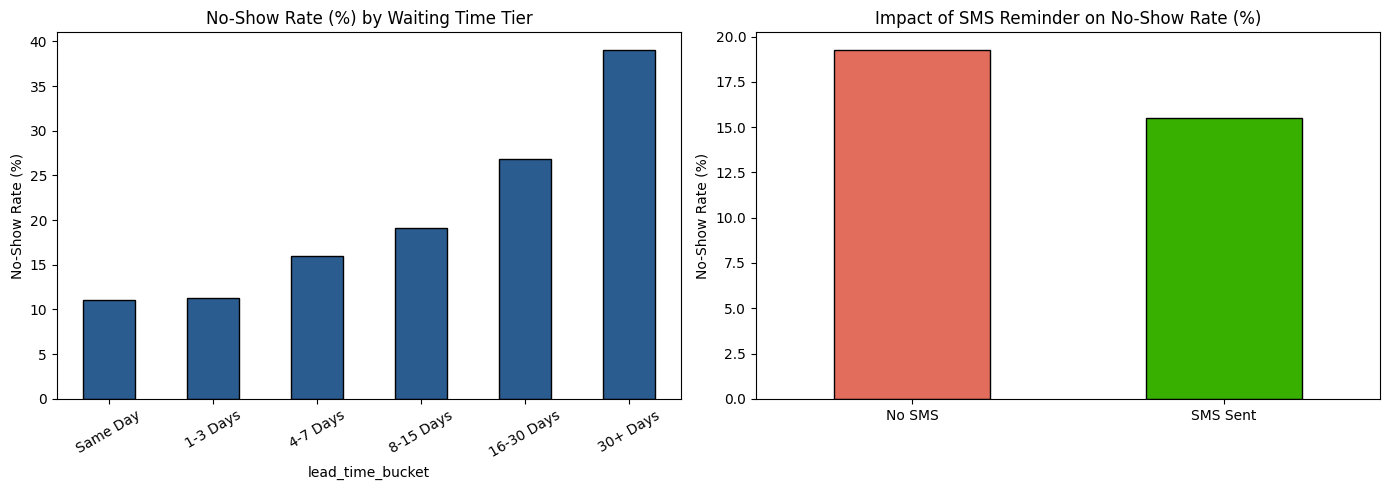

In [5]:
# 5. Visual EDA
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

lead_rates = df.groupby('lead_time_bucket', observed=False)['target'].mean() * 100
lead_rates.plot(kind='bar', ax=axes[0], color='#2b5c8f', edgecolor='black')
axes[0].set_title('No-Show Rate (%) by Waiting Time Tier')
axes[0].set_ylabel('No-Show Rate (%)')
axes[0].tick_params(axis='x', rotation=30)

sms_rates = df.groupby('sms_received')['target'].mean() * 100
sms_rates.index = ['No SMS', 'SMS Sent']
sms_rates.plot(kind='bar', ax=axes[1], color=['#e26d5c', '#38b000'], edgecolor='black')
axes[1].set_title('Impact of SMS Reminder on No-Show Rate (%)')
axes[1].set_ylabel('No-Show Rate (%)')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [6]:
# 6. Machine Learning Model Training & Comparative Benchmark
feature_cols_num = ['age', 'lead_days', 'scholarship', 'hypertension', 'diabetes', 
                    'alcoholism', 'handicap', 'sms_received', 'comorbidity_count']
feature_cols_cat = ['gender', 'appointment_weekday', 'age_group', 'lead_time_bucket']

X = df[feature_cols_num + feature_cols_cat]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

num_pipe = Pipeline([('scaler', StandardScaler())])
cat_pipe = Pipeline([('encoder', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer([
    ('num', num_pipe, feature_cols_num),
    ('cat', cat_pipe, feature_cols_cat)
])

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
}

benchmark = []
best_model = None
best_auc = 0.0

for name, clf in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('classifier', clf)])
    pipe.fit(X_train, y_train)
    
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    
    auc = roc_auc_score(y_test, y_prob)
    f1 = f1_score(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)
    
    benchmark.append({
        'Model': name,
        'ROC-AUC': round(auc, 4),
        'F1-Score': round(f1, 4),
        'Accuracy': round(acc, 4)
    })
    
    if auc > best_auc:
        best_auc = auc
        best_model = pipe

pd.DataFrame(benchmark).sort_values(by='ROC-AUC', ascending=False)

,Model,ROC-AUC,F1-Score,Accuracy
0,Logistic Regression,0.6545,0.3633,0.611
2,Gradient Boosting,0.5881,0.0498,0.809
1,Random Forest,0.5544,0.1714,0.768


In [7]:
# 7. Export Best Model
os.makedirs('models', exist_ok=True)
export_path = 'models/best_healthcare_no_show_model.joblib'
joblib.dump(best_model, export_path)
print(f'Pipeline completed! Best model successfully saved to: {export_path}')

Pipeline completed! Best model successfully saved to: models/best_healthcare_no_show_model.joblib


In [8]:
import sqlite3
import pandas as pd

# 1. Connect to SQLite database (creates 'healthcare.db' in your project folder)
conn = sqlite3.connect("healthcare.db")

# 2. Read and prepare data for SQL tables
df_sql = pd.read_csv("sample_cleaned_appointments.csv")

# Standardize column names
df_sql.columns = [c.strip().replace('-', '_').replace(' ', '_').lower() for c in df_sql.columns]
rename_dict = {
    'patientid': 'patient_id',
    'appointmentid': 'appointment_id',
    'scheduledday': 'scheduled_day',
    'appointmentday': 'appointment_day',
    'hipertension': 'hypertension',
    'handcap': 'handicap'
}
df_sql = df_sql.rename(columns=rename_dict)

# Format dates and calculate lead days
df_sql['scheduled_day'] = pd.to_datetime(df_sql['scheduled_day'])
df_sql['appointment_day'] = pd.to_datetime(df_sql['appointment_day'])
df_sql = df_sql[(df_sql['age'] >= 0) & (df_sql['age'] <= 115)]
df_sql['lead_days'] = (df_sql['appointment_day'].dt.normalize() - df_sql['scheduled_day'].dt.normalize()).dt.days
df_sql = df_sql[df_sql['lead_days'] >= 0]
df_sql['is_no_show'] = (df_sql['no_show'].str.strip().str.lower() == 'yes').astype(int)

# Categorize lead time
def categorize_lead(days):
    if days == 0:
        return 'Same Day'
    elif 1 <= days <= 3:
        return 'Short Notice (1-3 d)'
    elif 4 <= days <= 14:
        return 'Medium Notice (4-14 d)'
    else:
        return 'Long Notice (>14 d)'

df_sql['lead_time_category'] = df_sql['lead_days'].apply(categorize_lead)

# 3. Create the SQLite table
df_sql.to_sql("appointments_cleaned", conn, if_exists="replace", index=False)
print("SQLite Database created and table 'appointments_cleaned' loaded successfully!")

SQLite Database created and table 'appointments_cleaned' loaded successfully!


In [9]:
query_1 = """
SELECT 
    COUNT(*) AS total_appointments,
    COUNT(DISTINCT patient_id) AS unique_patients,
    SUM(is_no_show) AS total_no_shows,
    ROUND(AVG(is_no_show) * 100.0, 2) AS overall_no_show_rate_pct,
    ROUND(AVG(lead_days), 1) AS avg_lead_days,
    ROUND(AVG(age), 1) AS avg_patient_age
FROM appointments_cleaned;
"""

pd.read_sql_query(query_1, conn)

,total_appointments,unique_patients,total_no_shows,overall_no_show_rate_pct,avg_lead_days,avg_patient_age
0,5000,4988,897,17.94,9.5,44.6


In [10]:
query_2 = """
SELECT 
    sms_received,
    CASE WHEN sms_received = 1 THEN 'SMS Sent' ELSE 'No SMS' END AS reminder_status,
    COUNT(*) AS total_booked,
    SUM(is_no_show) AS no_shows,
    ROUND(AVG(is_no_show) * 100.0, 2) AS no_show_rate_pct
FROM appointments_cleaned
GROUP BY sms_received
ORDER BY sms_received DESC;
"""

pd.read_sql_query(query_2, conn)

,sms_received,reminder_status,total_booked,no_shows,no_show_rate_pct
0,1,SMS Sent,1772,275,15.52
1,0,No SMS,3228,622,19.27


In [11]:
query_3 = """
SELECT 
    lead_time_category,
    COUNT(*) AS total_appointments,
    SUM(is_no_show) AS no_shows,
    ROUND(AVG(is_no_show) * 100.0, 2) AS no_show_rate_pct
FROM appointments_cleaned
GROUP BY lead_time_category
ORDER BY no_show_rate_pct DESC;
"""

pd.read_sql_query(query_3, conn)

,lead_time_category,total_appointments,no_shows,no_show_rate_pct
0,Long Notice (>14 d),1119,320,28.60
1,Medium Notice (4-14 d),2278,397,17.43
2,Short Notice (1-3 d),1134,128,11.29
3,Same Day,469,52,11.09


In [12]:
query_4 = """
SELECT 
    neighbourhood,
    COUNT(*) AS total_appointments,
    SUM(is_no_show) AS no_shows,
    ROUND(AVG(is_no_show) * 100.0, 2) AS no_show_rate_pct
FROM appointments_cleaned
GROUP BY neighbourhood
HAVING COUNT(*) >= 200
ORDER BY no_show_rate_pct DESC
LIMIT 10;
"""

pd.read_sql_query(query_4, conn)

,neighbourhood,total_appointments,no_shows,no_show_rate_pct
0,MATA DA PRAIA,659,133,20.18
1,JARDIM DA PENHA,621,116,18.68
2,TABUAZEIRA,662,123,18.58
3,CENTRO,589,108,18.34
4,PRAIA DO CANTO,627,111,17.70
5,SANTO ANTONIO,615,105,17.07
6,JESUS DE NAZARETH,608,101,16.61
7,MARUIPE,619,100,16.16


In [13]:
query_5 = """
SELECT 
    hypertension,
    diabetes,
    scholarship,
    COUNT(*) AS total_patients,
    SUM(is_no_show) AS total_no_shows,
    ROUND(AVG(is_no_show) * 100.0, 2) AS no_show_rate_pct
FROM appointments_cleaned
GROUP BY hypertension, diabetes, scholarship
ORDER BY total_patients DESC;
"""

pd.read_sql_query(query_5, conn)

,hypertension,diabetes,scholarship,total_patients,total_no_shows,no_show_rate_pct
0,0,0,0,2925,504,17.23
1,1,0,0,974,175,17.97
2,1,1,0,360,61,16.94
3,0,0,1,325,76,23.38
4,0,1,0,250,39,15.60
5,1,0,1,105,26,24.76
6,1,1,1,34,11,32.35
7,0,1,1,27,5,18.52


In [14]:
# 1. Use the trained AI model to calculate no-show risk for every patient
df['predicted_risk_prob'] = best_model.predict_proba(X)[:, 1]

# 2. Assign Risk Categories
def assign_tier(prob):
    if prob >= 0.35:
        return 'High Risk'
    elif prob >= 0.20:
        return 'Medium Risk'
    else:
        return 'Low Risk'

df['ai_risk_tier'] = df['predicted_risk_prob'].apply(assign_tier)

# 3. Export the enhanced file for Power BI
df.to_csv("appointments_with_ai_predictions.csv", index=False)
print("Saved! 'appointments_with_ai_predictions.csv' is ready for Power BI.")

Saved! 'appointments_with_ai_predictions.csv' is ready for Power BI.
